# Mamíferos de Colombia — Semana 15: Auditoría del modelo final
**Integrantes:** Jaime Andrés Ortega Cadena · David Alejandro Muñoz Carmona

**Modelo auditado:** el que corre en la app. Es el estudiante **MobileNetV3-Large destilado** (224 px, mismos pesos que `mamiferos.tflite`) más el **ajuste por ubicación** del departamento. Se audita con las **2.458 fotos de prueba** (solo de Colombia, nunca vistas en el entrenamiento, separadas por registro GBIF).

| Sección | Qué responde |
|---|---|
| 5 | Precision, recall y F1 **por clase** |
| 6 | **Matriz de confusión** y los **pares que más se confunden** |
| 7 | Curvas **ROC** y **Precision-Recall**, y el **umbral de confianza** para responder «no estoy seguro» |
| 8 | Evaluación con **tres semillas** (media y desviación) |
| 9 | **Robustez:** desenfoque, poca luz, oclusión y otro fondo |
| 10 | **Grad-CAM** de 10 aciertos y 10 errores: dónde mira el modelo |
| 11 | **Prueba en la app** con 60 fotos reales de la región que el modelo nunca vio (CSV exportado desde la app) |
| 12 | Resumen en `resultados_auditoria.json` para el informe |

**Entradas en Kaggle (panel derecho → *Input*):**
1. Dataset `mamiferos-colombia-40`.
2. La salida del cuaderno `notebook901900824d`, que trae `estudiante_mobilenetv3.keras`.
3. Los modelos del entrenamiento (`modelo-mamiferos-v2` y la salida de `notebook5bd9742cb0`), que traen `division_dataset.csv`, la división exacta.
4. *(Opcional)* un dataset con `S15_PruebaCampo_Ortega_Munoz.csv`, el CSV que exporta la app.

*Accelerator* → GPU T4 · *Run All* (unos 15 minutos).

---
# 0–3. Configuración, ingesta, auditoría, división y lectura (idénticas al proyecto)

In [1]:
# 0.1 CONFIGURACIÓN (la misma del proyecto)
import os, sys, io, json, time, math, random, shutil, zipfile, hashlib, logging, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

EN_KAGGLE = Path("/kaggle/input").exists()

# ---------- Datos ----------
FRAC_VAL, FRAC_TEST = 0.15, 0.15       # validación y prueba: SOLO fotos de Colombia, separadas por registro (gbifID)
MAX_TRAIN_POR_CLASE = 1200             # tope en entrenamiento para que la ardilla colirroja (2.452) no domine

# ---------- Modelo profesor (Transfer Learning) ----------
MODELO_BASE = "EfficientNetV2S"
IMG_SIZE = 260
BATCH = 32
DENSA = 512                            # neuronas de la capa densa antes de la salida
DROPOUT_1, DROPOUT_2 = 0.40, 0.30      # anti-overfitting
REGULARIZACION, FACTOR_REG = "l2", 1e-4   # "l1", "l2", "l1_l2" o None  (penaliza los pesos grandes)
LABEL_SMOOTHING = 0.10

# ---------- Entrenamiento ----------
EPOCAS_ETAPA1 = 10                     # etapa 1: base congelada, solo se entrena la cabeza
EPOCAS_TOTALES = 60                    # etapa 2: ajuste fino de la parte alta de la base (épocas 11 a 60 = 50 épocas)
LR_ETAPA1, LR_ETAPA2 = 1e-3, 1e-4      # optimizador Adam
FRACCION_AJUSTE_FINO = 0.60            # se descongela el 60 % final de las capas de la base
PACIENCIA = 12                         # EarlyStopping: para si val_accuracy no mejora en 12 épocas
EPOCA_MINIMA = 50                      # EarlyStopping no puede detener el entrenamiento antes de la época 50
META_ACCURACY = 0.94

MODO_PRUEBA = False                    # True = corrida corta de demostración (pocos lotes, 2 épocas) para verificar el pipeline
SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("Kaggle:", EN_KAGGLE, "| modelo:", MODELO_BASE, f"{IMG_SIZE}px | épocas: {EPOCAS_ETAPA1} + {EPOCAS_TOTALES - EPOCAS_ETAPA1} = {EPOCAS_TOTALES}",
      "| MODO_PRUEBA" if MODO_PRUEBA else "")

Kaggle: True | modelo: EfficientNetV2S 260px | épocas: 10 + 50 = 60 


In [2]:
# 0.2 Entorno: GPU, TensorFlow/Keras, carpetas de salida y LOG
import tensorflow as tf
import keras
from keras import layers, regularizers
from IPython.display import display

BASE_SALIDA = Path("/kaggle/working") if EN_KAGGLE else Path.cwd()
SALIDA = BASE_SALIDA / "auditoria"
EVI = SALIDA / "evidencia"
for p in [SALIDA, EVI, SALIDA / "logs"]:
    p.mkdir(parents=True, exist_ok=True)

log = logging.getLogger("ENTRENAMIENTO"); log.setLevel(logging.INFO); log.handlers.clear(); log.propagate = False
_fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%Y-%m-%d %H:%M:%S")
_fh = logging.FileHandler(SALIDA / "logs" / f"entrenamiento_{datetime.now():%Y%m%d_%H%M%S}.log", encoding="utf-8")
_sh = logging.StreamHandler(sys.stdout)
for h in (_fh, _sh):
    h.setFormatter(_fmt); log.addHandler(h)

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    keras.mixed_precision.set_global_policy("mixed_float16")     # ~2x más rápido en GPU T4
keras.utils.set_random_seed(SEED)
log.info("=" * 70)
log.info(f"SESIÓN DE ENTRENAMIENTO | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
         f"GPU: {[g.name for g in GPUS] or 'NINGUNA'} | precisión: {keras.mixed_precision.global_policy().name}")
log.info(f"Salidas en: {SALIDA}")
if not GPUS:
    print("⚠️  No hay GPU. Panel derecho → Session options → Accelerator: GPU T4 x2 (requiere celular verificado).")
keras.mixed_precision.set_global_policy("float32")     # la auditoría usa float32 (Grad-CAM y comparaciones exactas)

2026-11-12 21:46:40 | INFO    | ======================================================================
2026-11-12 21:46:40 | INFO    | SESIÓN DE ENTRENAMIENTO | TensorFlow 2.21.0 | Keras 3.13.2 | GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1'] | precisión: mixed_float16
2026-11-12 21:46:40 | INFO    | Salidas en: /kaggle/working/auditoria


In [3]:
# 1.1 Ingesta: ubicar el dataset subido a Kaggle (Kaggle descomprime el ZIP solo) y leer metadata.csv
RAIZ = Path("/kaggle/input") if EN_KAGGLE else Path.cwd()
encontrados = sorted(RAIZ.rglob("metadata.csv"))
if encontrados:
    DATOS = encontrados[0].parent
else:                                                  # por si el ZIP no se descomprimió
    zips = sorted(RAIZ.rglob("*.zip"))
    assert zips, "No encuentro el dataset. Panel derecho → Input → Add Input → Your Datasets → mamiferos-colombia-40"
    DATOS = Path("/tmp/datos")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(DATOS)
meta = pd.read_csv(DATOS / "metadata.csv")
carpeta_img = DATOS / "dataset" if (DATOS / "dataset").exists() else DATOS
meta["ruta"] = meta["archivo"].map(lambda a: str(carpeta_img / a))
log.info(f"Dataset en: {DATOS}")
log.info(f"INGESTA: {len(meta)} imágenes | {meta.clase.nunique()} clases | "
         f"Colombia {int((meta.origen == 'colombia').sum())} | Latinoamérica {int((meta.origen != 'colombia').sum())}")

2026-11-12 21:46:45 | INFO    | Dataset en: /kaggle/input/datasets/davida29/mamiferos-colombia-40
2026-11-12 21:46:45 | INFO    | INGESTA: 23374 imágenes | 40 clases | Colombia 16147 | Latinoamérica 7227


In [4]:
# 1.2 Auditoría automática de la ingesta (limpieza antes de entrenar)
def auditar(ruta):
    p = Path(ruta)
    if not p.exists():
        return "no_existe", ""
    data = p.read_bytes()
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            w, h = im.size
    except Exception:
        return "corrupta", ""
    if min(w, h) < 64:
        return "muy_pequena", ""
    return "", hashlib.sha256(data).hexdigest()

t0 = time.time()
res = [auditar(r) for r in meta["ruta"]]
meta["problema"] = [r[0] for r in res]; meta["sha256"] = [r[1] for r in res]
dup = meta["sha256"].ne("") & meta.duplicated("sha256", keep="first")
meta.loc[dup, "problema"] = "duplicado_exacto"
aud = meta["problema"].replace("", "OK").value_counts()
log.info(f"AUDITORÍA ({time.time() - t0:.0f} s): " + " | ".join(f"{k}={v}" for k, v in aud.items()))
display(aud.to_frame("imágenes"))
meta = meta[meta["problema"] == ""].reset_index(drop=True)

CLASES = sorted(meta["clase"].unique())
N_CLASES = len(CLASES)
IDX = {c: i for i, c in enumerate(CLASES)}
meta["y"] = meta["clase"].map(IDX)
NOMBRE = meta.drop_duplicates("clase").set_index("clase")["nombre_comun"].to_dict()
log.info(f"Imágenes válidas para entrenar: {len(meta)} | clases: {N_CLASES}")

2026-11-12 22:11:54 | INFO    | AUDITORÍA (1509 s): OK=23358 | muy_pequena=16


,imágenes
problema,
OK,23358
muy_pequena,16


2026-11-12 22:11:54 | INFO    | Imágenes válidas para entrenar: 23358 | clases: 40


In [5]:
# 2.1 División estratificada por clase y agrupada por registro GBIF
rng = np.random.default_rng(SEED)
meta["split"] = "train"
for c, d in meta.groupby("clase"):
    reg_fuera = set(d.loc[d["origen"] != "colombia", "gbifID"])     # registros de otros países: solo entrenamiento
    col = d[~d["gbifID"].isin(reg_fuera)]
    por_reg = col.groupby("gbifID").size()
    ids = por_reg.index.to_numpy().copy(); rng.shuffle(ids)
    total, acum, asign = int(por_reg.sum()), 0, {}
    for g in ids:
        asign[g] = "test" if acum < total * FRAC_TEST else ("val" if acum < total * (FRAC_TEST + FRAC_VAL) else "train")
        acum += int(por_reg[g])
    meta.loc[col.index, "split"] = col["gbifID"].map(asign).values

# Tope por clase en entrenamiento (se priorizan las fotos de Colombia)
meta["_azar"] = rng.random(len(meta))
tr = meta[meta.split == "train"].sort_values(["clase", "origen", "_azar"],
                                             key=lambda s: (s != "colombia") if s.name == "origen" else s)
sobran = tr.groupby("clase").cumcount() >= MAX_TRAIN_POR_CLASE
meta.loc[tr.index[sobran.values], "split"] = "sin_usar"

# Verificación: ningún registro GBIF puede estar en dos grupos
g = {s: set(meta.loc[meta.split == s, "gbifID"]) for s in ["train", "val", "test"]}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"]), "¡Fuga de datos!"
assert (meta.loc[meta.split.isin(["val", "test"]), "origen"] == "colombia").all()

tabla_split = pd.crosstab(meta["clase"], meta["split"]).reindex(columns=["train", "val", "test", "sin_usar"], fill_value=0)
display(tabla_split)
tabla_split.to_csv(EVI / "division_por_clase.csv", encoding="utf-8-sig")
meta.drop(columns=["_azar"]).to_csv(SALIDA / "division_dataset.csv", index=False, encoding="utf-8-sig")
cuenta = meta["split"].value_counts()
log.info("DIVISIÓN por gbifID (sin fuga de datos ✓): " + " | ".join(f"{k}={cuenta.get(k, 0)}" for k in ["train", "val", "test", "sin_usar"]))

split,train,val,test,sin_usar
clase,,,,
ardilla_andina,156,34,34,0
ardilla_colirroja,1200,366,370,516
armadillo,637,14,14,0
armadillo_coletrapo,145,9,12,0
capuchino_cariblanco,459,20,20,0
capuchino_santa_marta,263,57,58,0
chiguiro,271,58,59,0
chucha_comun,462,99,100,0
curi,292,63,63,0


2026-11-12 22:11:55 | INFO    | DIVISIÓN por gbifID (sin fuga de datos ✓): train=17960 | val=2424 | test=2458 | sin_usar=516


In [6]:
# 2.2 Pesos por clase (compensan el desbalance): peso = N / (K · n_clase), limitado entre 0.5 y 5
n_tr = meta[meta.split == "train"].groupby("y").size().reindex(range(N_CLASES), fill_value=1)
PESOS = np.clip(n_tr.sum() / (N_CLASES * n_tr), 0.5, 5.0)
meta["peso"] = meta["y"].map(PESOS)
display(pd.DataFrame({"clase": CLASES, "imagenes_train": n_tr.values, "peso": PESOS.round(2).values})
          .sort_values("peso", ascending=False).head(10))
log.info(f"Pesos por clase: mínimo {PESOS.min():.2f} ({CLASES[int(PESOS.idxmin())]}) | "
         f"máximo {PESOS.max():.2f} ({CLASES[int(PESOS.idxmax())]})")

,clase,imagenes_train,peso
14,mico_cariblanco,111,4.05
3,armadillo_coletrapo,145,3.10
0,ardilla_andina,156,2.88
11,guagua_lapa,219,2.05
38,zaino,231,1.94
33,tamandua_sureno,231,1.94
35,titi_gris,251,1.79
23,ocelote,251,1.79
32,tamandua,263,1.71
5,capuchino_santa_marta,263,1.71


2026-11-12 22:16:44 | INFO    | Pesos por clase: mínimo 0.50 (ardilla_colirroja) | máximo 4.05 (mico_cariblanco)


In [7]:
# 3.1 Lectura eficiente con tf.data (paralela + prefetch)
AUTOTUNE = tf.data.AUTOTUNE

def leer_imagen(ruta, size):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    return tf.image.resize(img, (size, size), antialias=True)          # float32 en 0..255

def hacer_ds(df, size=IMG_SIZE, entrenamiento=False):
    if entrenamiento:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32"),
                                                 df["peso"].values.astype("float32")))
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda r, y, w: (leer_imagen(r, size), tf.one_hot(y, N_CLASES), w), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["y"].values.astype("int32")))
        ds = ds.map(lambda r, y: (leer_imagen(r, size), tf.one_hot(y, N_CLASES)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

TRAIN = meta[meta.split == "train"].reset_index(drop=True)
VAL = meta[meta.split == "val"].reset_index(drop=True)
TEST = meta[meta.split == "test"].reset_index(drop=True)
ds_train, ds_val, ds_test = hacer_ds(TRAIN, entrenamiento=True), hacer_ds(VAL), hacer_ds(TEST)
if MODO_PRUEBA:
    ds_train, ds_val, ds_test = ds_train.take(15), ds_val.take(5), ds_test.take(5)
log.info(f"tf.data listo | train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)} | lote {BATCH} | "
         f"{math.ceil(len(TRAIN) / BATCH)} pasos por época")

2026-11-12 22:16:49 | INFO    | tf.data listo | train 17960 | val 2424 | test 2458 | lote 32 | 562 pasos por época


In [8]:
# 3.2 La división EXACTA con la que se entrenó (archivo por archivo)
_todas = sorted(Path("/kaggle/input").rglob("division_dataset.csv"))
_ent = [f for f in _todas if "entrenamiento" in f.parts]     # las de los modelos entrenados; si no hay, cualquiera
divs = {f: pd.read_csv(f) for f in (_ent or _todas)}
assert divs, "No encontré division_dataset.csv en las entradas"
ref_f, ref = next(iter(divs.items()))
ref = ref.set_index("archivo")["split"]
for f, d in divs.items():
    s = d.set_index("archivo")["split"]
    igual = all(set(s[s == g].index) == set(ref[ref == g].index) for g in ["val", "test"])
    log.info(f"División de {f.parts[-3]}: {'✓ igual' if igual else '✗ DIFERENTE'} a la de {ref_f.parts[-3]}")
    assert igual, "Los modelos de entrada no se entrenaron con la misma división"
meta["split"] = meta["archivo"].map(ref).fillna("sin_usar")
n_tr = meta[meta.split == "train"].groupby("y").size().reindex(range(N_CLASES), fill_value=1)
PESOS = np.clip(n_tr.sum() / (N_CLASES * n_tr), 0.5, 5.0)
meta["peso"] = meta["y"].map(PESOS)
TRAIN = meta[meta.split == "train"].reset_index(drop=True)
VAL = meta[meta.split == "val"].reset_index(drop=True)
TEST = meta[meta.split == "test"].reset_index(drop=True)
ds_train, ds_val, ds_test = hacer_ds(TRAIN, entrenamiento=True), hacer_ds(VAL), hacer_ds(TEST)
log.info(f"Se usa la división EXACTA del entrenamiento: train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)}")

2026-11-12 22:16:56 | INFO    | División de modelo-mamiferos-v2: ✓ igual a la de modelo-mamiferos-v2
2026-11-12 22:16:56 | INFO    | División de notebook5bd9742cb0: ✓ igual a la de modelo-mamiferos-v2
2026-11-12 22:16:57 | INFO    | Se usa la división EXACTA del entrenamiento: train 17960 | val 2424 | test 2458


---
# 4. Modelo final y sus predicciones

In [9]:
# 4.1 Cargar el estudiante destilado (los mismos pesos que el mamiferos.tflite de la app)
cand = sorted(Path("/kaggle/input").rglob("estudiante_mobilenetv3.keras"))
assert cand, "No encuentro estudiante_mobilenetv3.keras: agrega como Input la salida de notebook901900824d"
MODELO = keras.models.load_model(cand[0], compile=False)
IMG_EST = MODELO.input_shape[1]
log.info(f"Modelo final: {cand[0]} | entrada {IMG_EST} px | {MODELO.count_params():,} parámetros")

def predecir(df, transformar=None, seed=0):
    ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, np.arange(len(df))))
    ds = ds.map(lambda r, i: (leer_imagen(r, IMG_EST), i), num_parallel_calls=AUTOTUNE).batch(64)
    if transformar is not None:
        ds = ds.map(lambda x, i: (transformar(x, i, seed), i), num_parallel_calls=AUTOTUNE)
    return MODELO.predict(ds.map(lambda x, i: x).prefetch(AUTOTUNE), verbose=0).astype("float32")

2026-11-12 22:17:07 | INFO    | Modelo final: /kaggle/input/notebooks/davida29/notebook901900824d/ensamble/estudiante_mobilenetv3.keras | entrada 224 px | 3,034,792 parámetros


In [10]:
# 4.2 Ajuste por ubicación (igual que en la app): frecuencias por departamento SOLO de entrenamiento; α y λ con validación
import unicodedata
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix,
                             roc_curve, auc, precision_recall_curve, average_precision_score, roc_auc_score)
def norm_dep(s):
    def f(x):
        if not isinstance(x, str) or not x.strip():
            return "desconocido"
        x = "".join(c for c in unicodedata.normalize("NFD", x.lower()) if unicodedata.category(c) != "Mn")
        for q in ["departamento de ", "departamento del ", "depto. de ", "depto ", "departamento "]:
            x = x.replace(q, "")
        return x.strip()
    return s.map(f)
CONTEO = pd.crosstab(norm_dep(TRAIN["departamento"]), TRAIN["y"]).reindex(columns=range(N_CLASES), fill_value=0)
CONTEO = CONTEO.drop(index="desconocido", errors="ignore")
def con_lugar(p, deps, alpha, lam):
    p_dep = (CONTEO + alpha).div(CONTEO.sum(1) + alpha * N_CLASES, axis=0)
    glob = CONTEO.sum(0) + alpha
    r = p_dep / (glob / glob.sum())
    f = np.vstack([r.loc[d].values if d in r.index else np.ones(N_CLASES) for d in norm_dep(deps)])
    q = p * f ** lam
    return q / q.sum(1, keepdims=True)

t0 = time.time()
Y = {"val": VAL["y"].values, "test": TEST["y"].values}
P_IMG = {"val": predecir(VAL), "test": predecir(TEST)}
acc = lambda p, g: float((p.argmax(1) == Y[g]).mean())
grid = sorted(((acc(con_lugar(P_IMG["val"], VAL["departamento"], a, l), "val"), -l, a, l)
               for a in [1, 3, 10] for l in [0, 0.25, 0.5, 0.75, 1.0]), reverse=True)
A_LUG, L_LUG = grid[0][2], grid[0][3]
P_FIN = {"val": con_lugar(P_IMG["val"], VAL["departamento"], A_LUG, L_LUG),
         "test": con_lugar(P_IMG["test"], TEST["departamento"], A_LUG, L_LUG)}
NOMBRES = [NOMBRE[c] for c in CLASES]
def metricas(p, y):
    yp = p.argmax(1)
    _, _, f1, _ = precision_recall_fscore_support(y, yp, labels=range(N_CLASES), average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(y, yp)), "f1_macro": float(f1),
            "top3": float((np.argsort(-p, 1)[:, :3] == y[:, None]).any(1).mean())}
M_IMG, M_FIN = metricas(P_IMG["test"], Y["test"]), metricas(P_FIN["test"], Y["test"])
log.info(f"Ubicación elegida con validación: alpha={A_LUG} lambda={L_LUG} | {time.time() - t0:.0f} s")
log.info(f"PRUEBA solo imagen: {M_IMG} | con ubicación (modelo final): {M_FIN}")
RES = {"modelo": "MobileNetV3-Large destilado + ubicación", "fotos_prueba": int(len(TEST)),
       "ubicacion": {"alpha": float(A_LUG), "lambda": float(L_LUG)}, "prueba_solo_imagen": M_IMG, "prueba_final": M_FIN}

E0000 00:00:1794521837.104442     140 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521837.273243     140 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521852.606982     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521852.778462     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521862.984443     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

2026-11-12 22:17:47 | INFO    | Ubicación elegida con validación: alpha=1 lambda=1.0 | 35 s
2026-11-12 22:17:47 | INFO    | PRUEBA solo imagen: {'accuracy': 0.9048006509357202, 'f1_macro': 0.8730179934791767, 'top3': 0.9776240846216436} | con ubicación (modelo final): {'accuracy': 0.9365337672904801, 'f1_macro': 0.9206393144806914, 'top3': 0.9796582587469488}


---
# 5. Precision, recall y F1 por clase
- **Precision:** de las veces que el modelo dijo «es esta especie», cuántas acertó. Baja precision = **falsos positivos**.
- **Recall:** de las fotos que sí eran de esa especie, cuántas encontró. Bajo recall = **falsos negativos**.
- **F1:** equilibrio entre las dos.

,especie,precision,recall,f1-score,support,f1 solo imagen
neque_negro,Ñeque negro,0.714,0.758,0.735,33,0.620
ardilla_andina,Ardilla andina,0.788,0.765,0.776,34,0.787
mapache_cangrejero,Mapache cangrejero,0.840,0.778,0.808,27,0.724
zaino,Zaino,0.907,0.765,0.830,51,0.787
puma,Puma,0.800,0.889,0.842,27,0.800
oso_de_anteojos,Oso de anteojos,0.923,0.800,0.857,15,0.750
mico_cariblanco,Mico cariblanco,0.815,0.917,0.863,24,0.864
tamandua_sureno,Tamandúa sureño,0.821,0.920,0.868,50,0.741
mono_ardilla_ecuatoriano,Mono ardilla ecuatoriano,0.864,0.927,0.894,41,0.771
pecari_labiado,Pecarí labiado,0.841,0.968,0.900,93,0.902


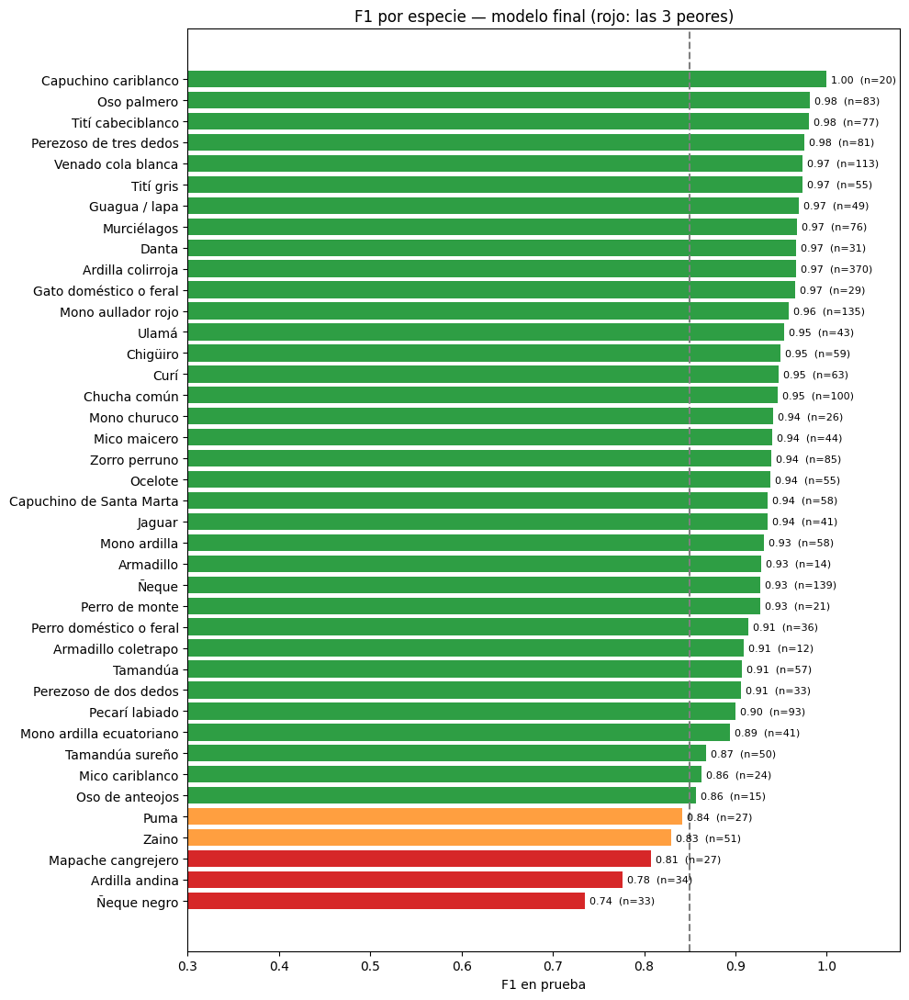

2026-11-12 22:43:44 | INFO    | Las 3 clases con peor F1: Ñeque negro F1=0.74 (P=0.71, R=0.76, n=33) | Ardilla andina F1=0.78 (P=0.79, R=0.76, n=34) | Mapache cangrejero F1=0.81 (P=0.84, R=0.78, n=27)


In [11]:
# 5.1 Tabla por clase (modelo final) y gráfica de F1
yt, yp = Y["test"], P_FIN["test"].argmax(1)
rep = pd.DataFrame(classification_report(yt, yp, labels=range(N_CLASES), target_names=CLASES, output_dict=True, zero_division=0)).T
POR_CLASE = rep.iloc[:N_CLASES].copy()
POR_CLASE.insert(0, "especie", NOMBRES)
POR_CLASE["support"] = POR_CLASE["support"].astype(int)
f1_img = precision_recall_fscore_support(yt, P_IMG["test"].argmax(1), labels=range(N_CLASES), zero_division=0)[2]
POR_CLASE["f1 solo imagen"] = f1_img
POR_CLASE = POR_CLASE.sort_values("f1-score")
POR_CLASE.to_csv(EVI / "metricas_por_clase.csv", encoding="utf-8-sig")
display(POR_CLASE.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "f1 solo imagen": "{:.3f}"})
        .background_gradient(subset=["f1-score"], cmap="RdYlGn", vmin=0.5, vmax=1))

fig, ax = plt.subplots(figsize=(10, 11))
colores = ["#d62728" if i < 3 else ("#ff9f40" if v < 0.85 else "#2e9e44") for i, v in enumerate(POR_CLASE["f1-score"])]
ax.barh(POR_CLASE["especie"], POR_CLASE["f1-score"], color=colores)
for i, (v, n) in enumerate(zip(POR_CLASE["f1-score"], POR_CLASE["support"])):
    ax.text(v + 0.005, i, f"{v:.2f}  (n={n})", va="center", fontsize=8)
ax.axvline(0.85, ls="--", c="gray"); ax.set_xlim(0.3, 1.08); ax.set_xlabel("F1 en prueba")
ax.set_title("F1 por especie — modelo final (rojo: las 3 peores)"); plt.tight_layout()
plt.savefig(EVI / "f1_por_clase.png", dpi=120); plt.show()
PEORES = POR_CLASE.head(3)
log.info("Las 3 clases con peor F1: " + " | ".join(f"{r.especie} F1={r['f1-score']:.2f} (P={r.precision:.2f}, R={r.recall:.2f}, n={r.support})"
                                                 for _, r in PEORES.iterrows()))
RES["peores_clases"] = [{"especie": r.especie, "precision": round(r.precision, 3), "recall": round(r.recall, 3),
                         "f1": round(r["f1-score"], 3), "fotos": int(r.support)} for _, r in PEORES.iterrows()]
RES["clases_f1_mayor_085"] = int((POR_CLASE["f1-score"] >= 0.85).sum())

---
# 6. Matriz de confusión y pares que más se confunden

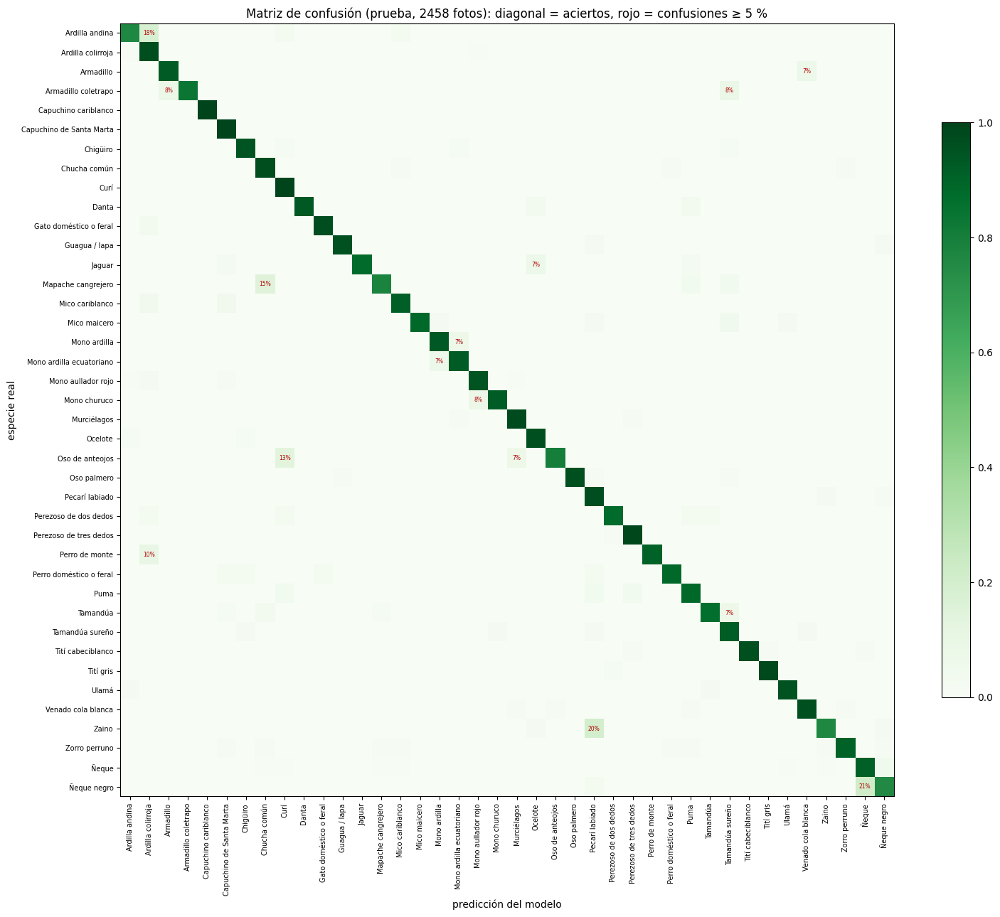

,errores,especie real,el modelo dijo,% de esa especie
0,10,Zaino,Pecarí labiado,19.6%
1,7,Ñeque negro,Ñeque,21.2%
2,6,Ñeque,Ñeque negro,4.3%
3,6,Ardilla andina,Ardilla colirroja,17.6%
4,4,Tamandúa,Tamandúa sureño,7.0%
5,4,Mono ardilla,Mono ardilla ecuatoriano,6.9%
6,4,Mapache cangrejero,Chucha común,14.8%
7,4,Ardilla colirroja,Ardilla andina,1.1%
8,3,Mono aullador rojo,Ardilla colirroja,2.2%
9,3,Mono ardilla ecuatoriano,Mono ardilla,7.3%


In [12]:
# 6.1 Matriz de confusión normalizada por fila (cada fila = la especie real suma 100 %)
cm = confusion_matrix(yt, yp, labels=range(N_CLASES))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
orden = np.argsort([n.lower() for n in NOMBRES])
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cmn[np.ix_(orden, orden)], cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASES)); ax.set_yticks(range(N_CLASES))
ax.set_xticklabels([NOMBRES[i] for i in orden], rotation=90, fontsize=7); ax.set_yticklabels([NOMBRES[i] for i in orden], fontsize=7)
for i in range(N_CLASES):
    for j in range(N_CLASES):
        v = cmn[orden[i], orden[j]]
        if i != j and v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=5.5, color="#b30000")
ax.set_xlabel("predicción del modelo"); ax.set_ylabel("especie real"); plt.colorbar(im, fraction=0.03)
ax.set_title(f"Matriz de confusión (prueba, {len(yt)} fotos): diagonal = aciertos, rojo = confusiones ≥ 5 %")
plt.tight_layout(); plt.savefig(EVI / "matriz_confusion.png", dpi=130); plt.show()

pares = [(cm[i, j], NOMBRES[i], NOMBRES[j], cm[i, j] / cm[i].sum()) for i in range(N_CLASES) for j in range(N_CLASES) if i != j and cm[i, j] > 0]
PARES = pd.DataFrame(sorted(pares, reverse=True)[:12], columns=["errores", "especie real", "el modelo dijo", "% de esa especie"])
display(PARES.style.format({"% de esa especie": "{:.1%}"}))
PARES.to_csv(EVI / "pares_mas_confundidos.csv", index=False, encoding="utf-8-sig")
RES["pares_mas_confundidos"] = [{"real": r["especie real"], "predicho": r["el modelo dijo"], "errores": int(r.errores),
                                 "porcentaje": round(float(r["% de esa especie"]), 3)} for _, r in PARES.head(6).iterrows()]

---
# 7. Curvas ROC y Precision-Recall, y el umbral para responder «no estoy seguro»
- **ROC / PR por clase (uno contra todos):** qué tan bien separa cada especie del resto.
- **¿La confianza sirve para detectar errores?** Si los errores tienen confianza baja, la app puede decir «no estoy seguro» y mostrar las 3 opciones en vez de afirmar una especie.
- El umbral se elige con **validación** (que las respuestas seguras acierten al menos el 97 %) y se comprueba en **prueba**.

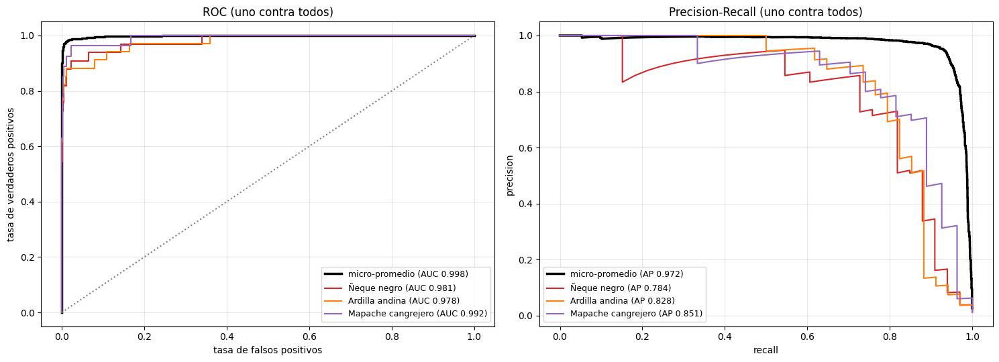

2026-11-12 22:44:29 | INFO    | AUC ROC macro (uno contra todos): 0.9966


In [13]:
# 7.1 ROC y Precision-Recall (micro-promedio y las 3 peores especies)
Yb = np.eye(N_CLASES)[yt]; pf = P_FIN["test"]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
fpr, tpr, _ = roc_curve(Yb.ravel(), pf.ravel()); axs[0].plot(fpr, tpr, lw=2.5, c="black", label=f"micro-promedio (AUC {auc(fpr, tpr):.3f})")
pr_, rc_, _ = precision_recall_curve(Yb.ravel(), pf.ravel())
axs[1].plot(rc_, pr_, lw=2.5, c="black", label=f"micro-promedio (AP {average_precision_score(Yb.ravel(), pf.ravel()):.3f})")
for (_, r), c in zip(PEORES.iterrows(), ["#d62728", "#ff7f0e", "#9467bd"]):
    k = CLASES.index(r.name)
    f_, t_, _ = roc_curve(Yb[:, k], pf[:, k]); axs[0].plot(f_, t_, c=c, label=f"{r.especie} (AUC {auc(f_, t_):.3f})")
    p_, r2, _ = precision_recall_curve(Yb[:, k], pf[:, k]); axs[1].plot(r2, p_, c=c, label=f"{r.especie} (AP {average_precision_score(Yb[:, k], pf[:, k]):.3f})")
axs[0].plot([0, 1], [0, 1], ls=":", c="gray"); axs[0].set_xlabel("tasa de falsos positivos"); axs[0].set_ylabel("tasa de verdaderos positivos")
axs[1].set_xlabel("recall"); axs[1].set_ylabel("precision")
axs[0].set_title("ROC (uno contra todos)"); axs[1].set_title("Precision-Recall (uno contra todos)")
for ax in axs: ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="lower right" if ax is axs[0] else "lower left")
plt.tight_layout(); plt.savefig(EVI / "roc_pr.png", dpi=120); plt.show()
AUC_MACRO = roc_auc_score(yt, pf, multi_class="ovr", average="macro", labels=range(N_CLASES))
log.info(f"AUC ROC macro (uno contra todos): {AUC_MACRO:.4f}")
RES["auc_roc_macro"] = round(float(AUC_MACRO), 4)

,regla,umbral,cobertura,acc_respondidas,acc_no_seguras,top3_no_seguras
0,"app: confianza media (≥ 0,50)",0.500000,92.6%,96.8%,53.8%,80.8%
1,umbral elegido (≥ 0.61),0.610000,89.2%,97.4%,62.8%,86.1%
2,"app: confianza alta (≥ 0,85)",0.850000,75.7%,98.8%,77.6%,92.8%


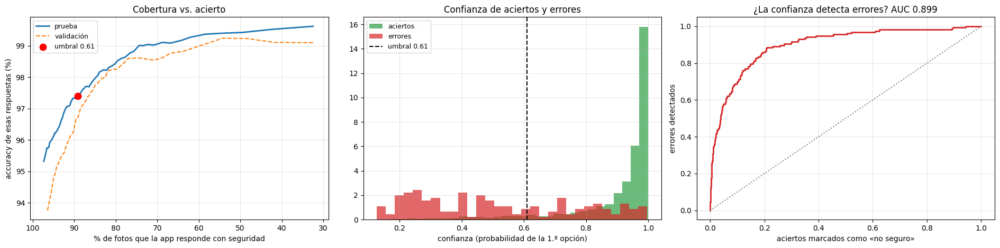

2026-11-12 22:44:34 | INFO    | UMBRAL «no estoy seguro» = 0.61 (validación: acierto ≥ 97%) → en prueba responde 89.2% de las fotos con 97.4% de acierto; en las «no seguras» la correcta está en el top-3 el 86.1%


In [14]:
# 7.2 Umbral de confianza para «no estoy seguro» (elegido con validación, comprobado en prueba)
META_SEGURO = 0.97
def cobertura(p, y, t):
    conf = p.max(1); ok = p.argmax(1) == y; resp = conf >= t
    return {"umbral": t, "cobertura": resp.mean(), "acc_respondidas": ok[resp].mean() if resp.any() else np.nan,
            "acc_no_seguras": ok[~resp].mean() if (~resp).any() else np.nan,
            "top3_no_seguras": (np.argsort(-p[~resp], 1)[:, :3] == y[~resp][:, None]).any(1).mean() if (~resp).any() else np.nan}
umbrales = np.round(np.arange(0.30, 0.99, 0.01), 2)
CV = pd.DataFrame([cobertura(P_FIN["val"], Y["val"], t) for t in umbrales])
validos = CV[CV["acc_respondidas"] >= META_SEGURO]
UMBRAL = float(validos["umbral"].min()) if len(validos) else 0.85
CT = pd.DataFrame([cobertura(P_FIN["test"], Y["test"], t) for t in umbrales])
sel = cobertura(P_FIN["test"], Y["test"], UMBRAL)
app = pd.DataFrame([cobertura(P_FIN["test"], Y["test"], t) for t in [0.5, UMBRAL, 0.85]])
app.insert(0, "regla", ["app: confianza media (≥ 0,50)", f"umbral elegido (≥ {UMBRAL:.2f})", "app: confianza alta (≥ 0,85)"])
display(app.style.format({c: "{:.1%}" for c in ["cobertura", "acc_respondidas", "acc_no_seguras", "top3_no_seguras"]}))

conf, ok = P_FIN["test"].max(1), P_FIN["test"].argmax(1) == Y["test"]
fpr_c, tpr_c, _ = roc_curve(~ok, -conf)
fig, axs = plt.subplots(1, 3, figsize=(19, 4.8))
axs[0].plot(CT["cobertura"] * 100, CT["acc_respondidas"] * 100, lw=2, label="prueba")
axs[0].plot(CV["cobertura"] * 100, CV["acc_respondidas"] * 100, lw=1.5, ls="--", label="validación")
axs[0].scatter([sel["cobertura"] * 100], [sel["acc_respondidas"] * 100], s=80, c="red", zorder=5, label=f"umbral {UMBRAL:.2f}")
axs[0].set_xlabel("% de fotos que la app responde con seguridad"); axs[0].set_ylabel("accuracy de esas respuestas (%)")
axs[0].set_title("Cobertura vs. acierto"); axs[0].invert_xaxis()
axs[1].hist(conf[ok], bins=30, alpha=0.7, label="aciertos", color="#2e9e44", density=True)
axs[1].hist(conf[~ok], bins=30, alpha=0.7, label="errores", color="#d62728", density=True)
axs[1].axvline(UMBRAL, c="black", ls="--", label=f"umbral {UMBRAL:.2f}"); axs[1].set_xlabel("confianza (probabilidad de la 1.ª opción)")
axs[1].set_title("Confianza de aciertos y errores")
axs[2].plot(fpr_c, tpr_c, lw=2, c="#d62728"); axs[2].plot([0, 1], [0, 1], ls=":", c="gray")
axs[2].set_xlabel("aciertos marcados como «no seguro»"); axs[2].set_ylabel("errores detectados")
axs[2].set_title(f"¿La confianza detecta errores? AUC {auc(fpr_c, tpr_c):.3f}")
for ax in axs: ax.grid(alpha=0.3)
axs[0].legend(fontsize=9); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(EVI / "umbral_no_estoy_seguro.png", dpi=120); plt.show()
log.info(f"UMBRAL «no estoy seguro» = {UMBRAL:.2f} (validación: acierto ≥ {META_SEGURO:.0%}) → en prueba responde {sel['cobertura']:.1%} "
         f"de las fotos con {sel['acc_respondidas']:.1%} de acierto; en las «no seguras» la correcta está en el top-3 el {sel['top3_no_seguras']:.1%}")
RES["umbral_no_seguro"] = {"umbral": UMBRAL, "meta_acierto": META_SEGURO, "cobertura_prueba": round(float(sel["cobertura"]), 4),
                           "acierto_respondidas": round(float(sel["acc_respondidas"]), 4),
                           "acierto_no_seguras": round(float(sel["acc_no_seguras"]), 4), "top3_no_seguras": round(float(sel["top3_no_seguras"]), 4),
                           "auc_confianza_detecta_errores": round(float(auc(fpr_c, tpr_c)), 4)}

---
# 8. Evaluación con tres semillas (media y desviación)
Volver a entrenar el estudiante tres veces cuesta unas 3 horas de GPU (65 minutos cada destilación). Por eso la variabilidad se mide sobre el **modelo final ya entrenado**, con tres semillas que cambian:
1. **la muestra de prueba**, remuestreada con reposición (*bootstrap*), del mismo tamaño;
2. **las perturbaciones aleatorias** de la sección 9: dónde cae la oclusión, el ruido de poca luz y el fondo de reemplazo.

Así se reporta cada métrica como **media ± desviación**.

In [15]:
# 8.1 Bootstrap con tres semillas
SEMILLAS = [42, 7, 2026]
filas = []
for s in SEMILLAS:
    idx = np.random.default_rng(s).integers(0, len(yt), len(yt))
    m = metricas(P_FIN["test"][idx], yt[idx]); m["semilla"] = s; filas.append(m)
SEM = pd.DataFrame(filas).set_index("semilla")
resumen = SEM.agg(["mean", "std"]).T
display(SEM.style.format("{:.4f}")); display(resumen.style.format("{:.4f}"))
for k, r in resumen.iterrows():
    log.info(f"Tres semillas — {k}: {r['mean']:.4f} ± {r['std']:.4f}")
RES["tres_semillas"] = {k: {"media": round(float(r["mean"]), 4), "desviacion": round(float(r["std"]), 4)} for k, r in resumen.iterrows()}

,accuracy,f1_macro,top3
semilla,,,
42,0.9341,0.9109,0.9776
7,0.9325,0.9180,0.9768
2026,0.9296,0.9125,0.9744


,mean,std
accuracy,0.9321,0.0023
f1_macro,0.9138,0.0037
top3,0.9763,0.0017


2026-11-12 22:44:38 | INFO    | Tres semillas — accuracy: 0.9321 ± 0.0023
2026-11-12 22:44:38 | INFO    | Tres semillas — f1_macro: 0.9138 ± 0.0037
2026-11-12 22:44:38 | INFO    | Tres semillas — top3: 0.9763 ± 0.0017


---
# 9. Robustez: desenfoque, poca luz, oclusión y otro fondo
Cada foto de prueba se altera de cuatro formas que pasan en las cámaras trampa y en el celular:
- **Desenfoque:** cámara movida o animal en movimiento (desenfoque gaussiano, σ = 3 px).
- **Poca luz:** amanecer, atardecer o noche sin infrarrojo (brillo × 0,30 y ruido del sensor).
- **Oclusión:** una rama o una hoja tapa parte del animal (un rectángulo que cubre entre el 20 % y el 35 % de la foto, en un lugar al azar).
- **Otro fondo:** el animal en un entorno distinto (se conserva el centro de la foto y el borde se reemplaza con el de otra foto).

Cada condición se evalúa con las **tres semillas** (media ± desviación).

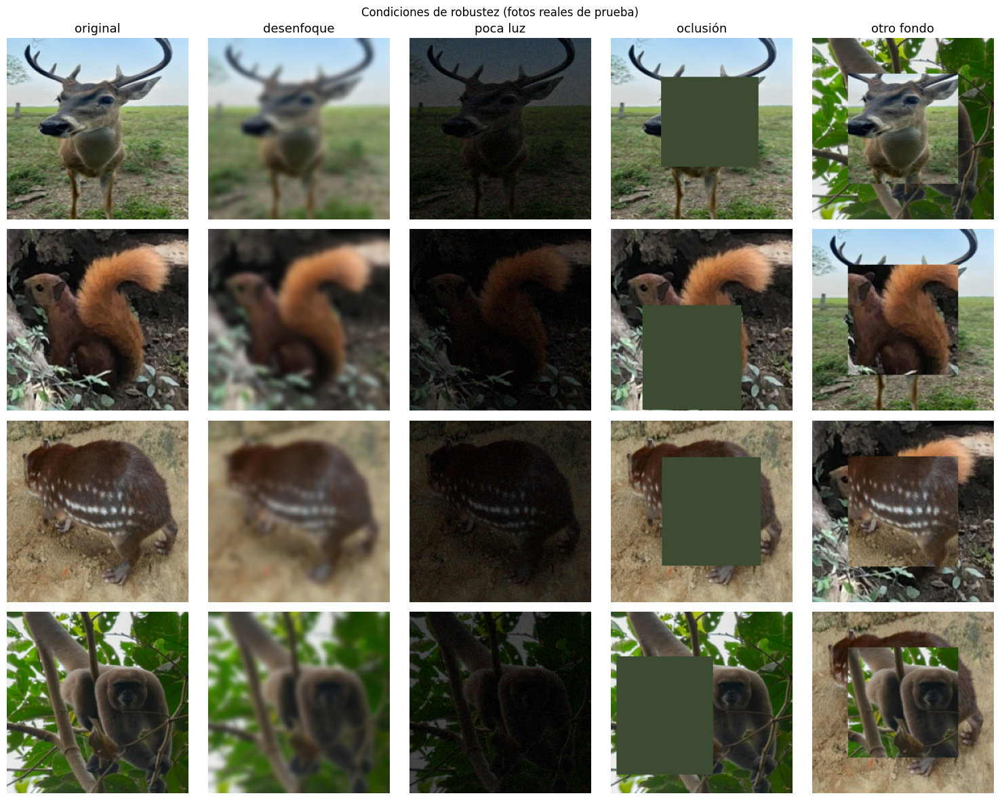

In [16]:
# 9.1 Transformaciones (sobre lotes de imágenes 0..255)
def _gauss(sigma, r=8):
    x = tf.range(-r, r + 1, dtype=tf.float32); k = tf.exp(-(x ** 2) / (2 * sigma ** 2)); k = k / tf.reduce_sum(k)
    k2 = k[:, None] * k[None, :]
    return tf.tile(k2[:, :, None, None], [1, 1, 3, 1])
K_BLUR = _gauss(3.0)
def desenfoque(x, i, s):
    return tf.nn.depthwise_conv2d(tf.pad(x, [[0, 0], [8, 8], [8, 8], [0, 0]], mode="REFLECT"), K_BLUR, [1, 1, 1, 1], "VALID")
def poca_luz(x, i, s):
    ruido = tf.random.stateless_normal(tf.shape(x), seed=[s, tf.cast(i[0], tf.int32)], stddev=6.0)
    return tf.clip_by_value(255.0 * (x / 255.0) ** 1.4 * 0.30 + ruido, 0, 255)
def oclusion(x, i, s):
    n = tf.shape(x)[0]; H = tf.cast(IMG_EST, tf.float32)
    u = tf.random.stateless_uniform([n, 4], seed=[s + 1, tf.cast(i[0], tf.int32)])
    area = 0.20 + 0.15 * u[:, 0]; asp = 0.6 + 0.8 * u[:, 1]
    h = tf.sqrt(area * asp) * H; w = tf.sqrt(area / asp) * H
    y0 = u[:, 2] * (H - h); x0 = u[:, 3] * (H - w)
    yy = tf.range(H)[None, :, None]; xx = tf.range(H)[None, None, :]
    m = (yy >= y0[:, None, None]) & (yy < (y0 + h)[:, None, None]) & (xx >= x0[:, None, None]) & (xx < (x0 + w)[:, None, None])
    return tf.where(m[..., None], tf.constant([60.0, 75.0, 50.0]), x)       # color de hoja/rama
def otro_fondo(x, i, s):
    otra = tf.roll(x, shift=1, axis=0)                                        # la foto vecina del lote (orden al azar)
    c = int(IMG_EST * 0.20)
    m = np.zeros((IMG_EST, IMG_EST, 1), "float32"); m[c:-c, c:-c] = 1
    m = tf.constant(m)
    return x * m + otra * (1 - m)
CONDICIONES = {"original": None, "desenfoque": desenfoque, "poca luz": poca_luz, "oclusión": oclusion, "otro fondo": otro_fondo}

# Ejemplo visual de cada condición
ej = TEST.sample(4, random_state=1)
lote = tf.stack([leer_imagen(r, IMG_EST) for r in ej["ruta"]]); ii = tf.constant([0])
fig, axs = plt.subplots(4, 5, figsize=(15, 12))
for j, (nom, f) in enumerate(CONDICIONES.items()):
    im = lote if f is None else f(lote, ii, 42)
    for k in range(4):
        axs[k, j].imshow(np.clip(im[k].numpy(), 0, 255).astype("uint8")); axs[k, j].axis("off")
        if k == 0: axs[k, j].set_title(nom, fontsize=13)
plt.suptitle("Condiciones de robustez (fotos reales de prueba)"); plt.tight_layout()
plt.savefig(EVI / "robustez_ejemplos.png", dpi=100); plt.show()

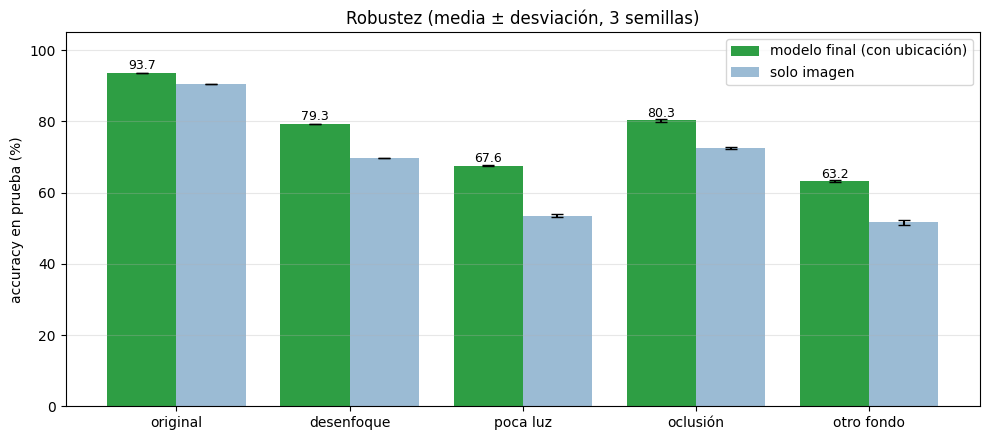

2026-11-12 22:54:29 | INFO    | Robustez lista (568 s)


In [17]:
# 9.2 Accuracy y F1 en cada condición × tres semillas
t0 = time.time(); filas = []
for s in SEMILLAS:
    orden_s = TEST.sample(frac=1, random_state=s).reset_index(drop=True)      # orden al azar: el «otro fondo» viene de otra especie
    y_s = orden_s["y"].values
    for nom, f in CONDICIONES.items():
        p = predecir(orden_s, f, s)
        pf_s = con_lugar(p, orden_s["departamento"], A_LUG, L_LUG)
        mi, mf = metricas(p, y_s), metricas(pf_s, y_s)
        filas.append({"semilla": s, "condición": nom, "accuracy": mf["accuracy"], "f1_macro": mf["f1_macro"], "top3": mf["top3"],
                      "accuracy solo imagen": mi["accuracy"]})
ROB = pd.DataFrame(filas)
ROB_R = ROB.groupby("condición", sort=False)[["accuracy", "f1_macro", "top3", "accuracy solo imagen"]].agg(["mean", "std"])
ROB_R[("caída vs original", "pts")] = (ROB_R[("accuracy", "mean")] - ROB_R.loc["original", ("accuracy", "mean")]) * 100
display(ROB_R.style.format("{:.4f}")); ROB.to_csv(EVI / "robustez_tres_semillas.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(10, 4.5)); xs = np.arange(len(CONDICIONES))
m_, s_ = ROB_R[("accuracy", "mean")] * 100, ROB_R[("accuracy", "std")] * 100
m2, s2 = ROB_R[("accuracy solo imagen", "mean")] * 100, ROB_R[("accuracy solo imagen", "std")] * 100
ax.bar(xs - 0.2, m_, 0.4, yerr=s_, capsize=4, color="#2e9e44", label="modelo final (con ubicación)")
ax.bar(xs + 0.2, m2, 0.4, yerr=s2, capsize=4, color="#9bbbd4", label="solo imagen")
for x, v in zip(xs, m_): ax.text(x - 0.2, v + 1, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(list(CONDICIONES)); ax.set_ylabel("accuracy en prueba (%)"); ax.set_ylim(0, 105)
ax.set_title("Robustez (media ± desviación, 3 semillas)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(EVI / "robustez.png", dpi=120); plt.show()
log.info(f"Robustez lista ({time.time() - t0:.0f} s)")
RES["robustez"] = {c: {"accuracy_media": round(float(ROB_R.loc[c, ("accuracy", "mean")]), 4),
                       "accuracy_desv": round(float(ROB_R.loc[c, ("accuracy", "std")]), 4),
                       "f1_media": round(float(ROB_R.loc[c, ("f1_macro", "mean")]), 4),
                       "caida_puntos": round(float(ROB_R.loc[c, ("caída vs original", "pts")]), 2)} for c in CONDICIONES}

---
# 10. Grad-CAM: dónde mira el modelo
Grad-CAM colorea las zonas de la foto que más empujaron la decisión de la red (rojo = más importante).
- **10 aciertos** al azar, de especies distintas.
- **10 errores**: los que el modelo cometió con **más confianza**, que son los más peligrosos para el usuario.

Se explica la red neuronal (solo imagen), que es la parte que «mira» la foto.

2026-11-12 23:02:48 | INFO    | Grad-CAM sobre la capa 'activation_39' de MobileNetV3Large; cabeza 'logits'


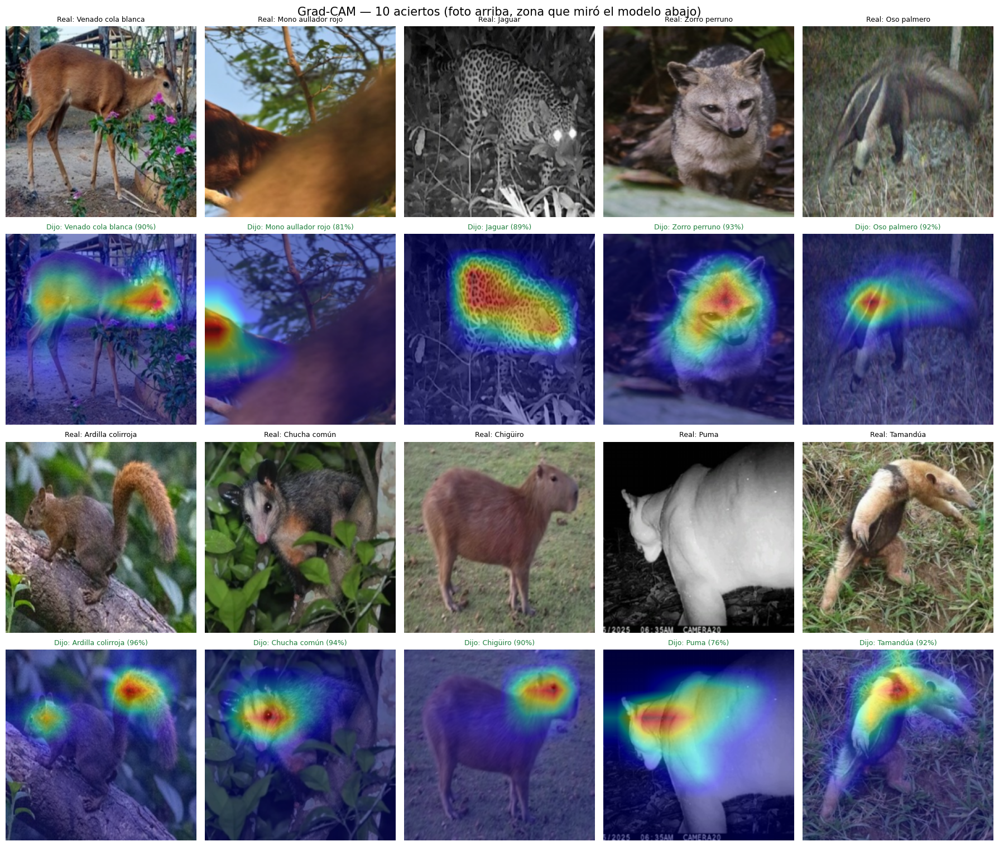

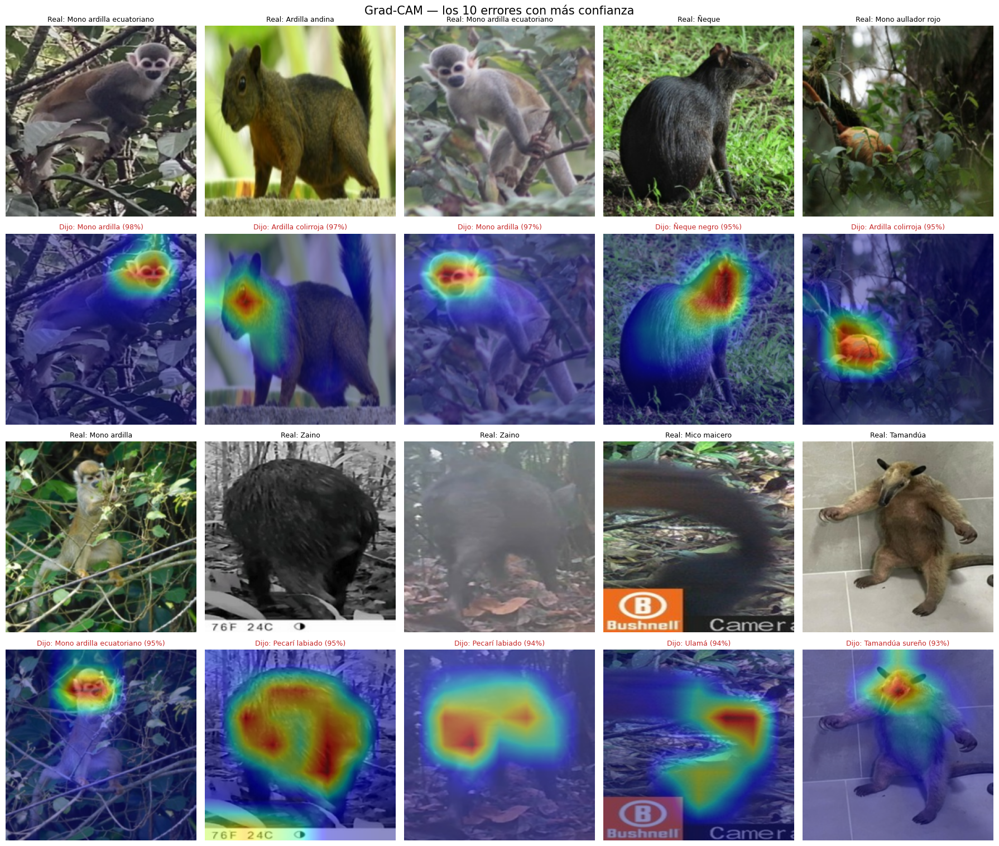

In [18]:
# 10.1 Grad-CAM sobre la última capa convolucional de MobileNetV3
base = next(l for l in MODELO.layers if isinstance(l, keras.Model))
capa_conv = next(l.name for l in reversed(base.layers) if len(l.output.shape) == 4)
modelo_grad = keras.Model(base.inputs, [base.get_layer(capa_conv).output, base.output])
densa = next(l for l in reversed(MODELO.layers) if isinstance(l, layers.Dense))
log.info(f"Grad-CAM sobre la capa '{capa_conv}' de {base.name}; cabeza '{densa.name}'")

def gradcam(img, clase):
    x = tf.convert_to_tensor(img[None], tf.float32)
    with tf.GradientTape() as tape:
        conv, vec = modelo_grad(x, training=False)
        tape.watch(conv)
        logit = densa(vec)[0, clase]
    g = tape.gradient(logit, conv)[0]
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * tf.reduce_mean(g, axis=(0, 1)), axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (IMG_EST, IMG_EST)).numpy()[..., 0]

pi = P_IMG["test"]; pred_i, conf_i = pi.argmax(1), pi.max(1)
rng_g = np.random.default_rng(SEED)
aciertos = [i for i in rng_g.permutation(np.where(pred_i == yt)[0])]
vistos, ACI = set(), []
for i in aciertos:
    if yt[i] not in vistos: ACI.append(i); vistos.add(yt[i])
    if len(ACI) == 10: break
ERR = list(np.where(pred_i != yt)[0][np.argsort(-conf_i[pred_i != yt])][:10])

def lamina(indices, titulo, archivo):
    fig, axs = plt.subplots(4, 5, figsize=(18, 15.5))
    for k, i in enumerate(indices):
        img = leer_imagen(TEST["ruta"].iloc[i], IMG_EST).numpy()
        cam = gradcam(img, int(pred_i[i]))
        a, b = axs[(k // 5) * 2, k % 5], axs[(k // 5) * 2 + 1, k % 5]
        a.imshow(img.astype("uint8")); b.imshow(img.astype("uint8")); b.imshow(cam, cmap="jet", alpha=0.45)
        ok = pred_i[i] == yt[i]
        a.set_title(f"Real: {NOMBRES[yt[i]]}", fontsize=9)
        b.set_title(f"Dijo: {NOMBRES[pred_i[i]]} ({conf_i[i]:.0%})", fontsize=9, color="#1b7f3a" if ok else "#c62828")
        a.axis("off"); b.axis("off")
    plt.suptitle(titulo, fontsize=15); plt.tight_layout(); plt.savefig(EVI / archivo, dpi=110); plt.show()
lamina(ACI, "Grad-CAM — 10 aciertos (foto arriba, zona que miró el modelo abajo)", "gradcam_aciertos.png")
lamina(ERR, "Grad-CAM — los 10 errores con más confianza", "gradcam_errores.png")
RES["gradcam_errores"] = [{"real": NOMBRES[yt[i]], "predicho": NOMBRES[pred_i[i]], "confianza": round(float(conf_i[i]), 3),
                           "archivo": TEST["archivo"].iloc[i]} for i in ERR]

---
# 11. Prueba en la app con fotos reales de la región
Se eligen **60 fotos del conjunto de prueba** (el modelo **nunca las vio** al entrenar), registradas en el **Tolima y los departamentos vecinos**, con hasta 2 por especie.
Cada foto lleva en su nombre la especie real (`07_jaguar.jpg`) y en sus metadatos el GPS del departamento donde se registró, para que la app aplique el ajuste por ubicación como en campo.

**Pasos:**
1. Correr la celda 11.0 y descargar `fotos_prueba_app.zip` (panel derecho → *Output*).
2. Pasar las fotos al celular (Google Drive → descargar) y, **con internet**, abrir la app → **Subir fotos** (máximo 30 a la vez, dos tandas).
3. En la app: **Ajustes → Exportar prueba de campo**. El CSV sale con archivo, clase real, predicción, confianza y tiempo de respuesta (ms).
4. Subir ese CSV como dataset, agregarlo como *Input* y correr la celda 11.1.

In [19]:
# 11.0 Selección de 60 fotos de prueba de la región (hasta 2 por especie) con GPS del departamento
from fractions import Fraction
from PIL import ExifTags
CAPITALES = {"tolima": (4.4389, -75.2322), "huila": (2.9273, -75.2819), "cundinamarca": (5.0221, -74.0058),
             "caldas": (5.0703, -75.5138), "quindio": (4.5339, -75.6811), "risaralda": (4.8133, -75.6961),
             "valle del cauca": (3.4516, -76.5320), "boyaca": (5.5353, -73.3678), "antioquia": (6.2442, -75.5812),
             "meta": (4.1420, -73.6266), "santander": (7.1193, -73.1227), "cauca": (2.4448, -76.6147), "narino": (1.2136, -77.2811),
             "caqueta": (1.6144, -75.6062), "magdalena": (11.2408, -74.1990), "choco": (5.6947, -76.6611),
             "amazonas": (-4.2153, -69.9406), "putumayo": (1.1492, -76.6464), "casanare": (5.3378, -72.3959),
             "cordoba": (8.7479, -75.8814), "bolivar": (10.3910, -75.4794), "norte de santander": (7.8939, -72.5078),
             "la guajira": (11.5444, -72.9072), "cesar": (10.4631, -73.2532), "sucre": (9.3047, -75.3978),
             "atlantico": (10.9685, -74.7813), "arauca": (7.0847, -70.7591), "vichada": (6.1890, -67.4859),
             "guaviare": (2.5729, -72.6459), "guainia": (3.8653, -67.9239), "vaupes": (1.2538, -70.2345)}
REGION = ["tolima", "huila", "cundinamarca", "caldas", "quindio", "risaralda", "valle del cauca"]
N_FOTOS, POR_ESPECIE = 60, 2
T = TEST.copy(); T["dep"] = norm_dep(T["departamento"]).values
T = T[T["dep"].isin(CAPITALES)]
rng_s = np.random.default_rng(SEED)
T["_azar"] = rng_s.random(len(T)); T["_region"] = (~T["dep"].isin(REGION)).astype(int)     # 0 = región, primero
T = T.sort_values(["_region", "_azar"])
elegidas = T.groupby("clase").head(POR_ESPECIE)
elegidas = elegidas.sort_values(["_region", "_azar"]).head(N_FOTOS).reset_index(drop=True)

def _dms(v):
    v = abs(v); d = int(v); m = int((v - d) * 60); s = ((v - d) * 60 - m) * 60
    return (Fraction(d), Fraction(m), Fraction(round(s * 100), 100))
DIR_PA = BASE_SALIDA / "fotos_prueba_app"; shutil.rmtree(DIR_PA, ignore_errors=True); DIR_PA.mkdir(parents=True)
filas = []
for k, r in elegidas.iterrows():
    lat, lon = CAPITALES[r["dep"]]
    nombre = f"{k + 1:02d}_{r['clase']}.jpg"
    with Image.open(r["ruta"]) as im:
        ex = Image.Exif()
        ex[ExifTags.IFD.GPSInfo] = {0: b"\x02\x02\x00\x00", 1: "N" if lat >= 0 else "S", 2: _dms(lat), 3: "W" if lon < 0 else "E", 4: _dms(lon)}
        im.convert("RGB").save(DIR_PA / nombre, quality=92, exif=ex)
    filas.append({"archivo_original": nombre, "clase_real": NOMBRE[r["clase"]], "departamento_registro": r["departamento"],
                  "en_region": r["dep"] in REGION, "gbifID": r.get("gbifID", ""), "archivo_dataset": r["archivo"]})
SELECCION = pd.DataFrame(filas)
SELECCION.to_csv(DIR_PA / "seleccion_prueba_app.csv", index=False, encoding="utf-8-sig")
shutil.make_archive(str(BASE_SALIDA / "fotos_prueba_app"), "zip", DIR_PA)
log.info(f"{len(SELECCION)} fotos para la app | {SELECCION.en_region.sum()} del Tolima y vecinos | "
         f"{SELECCION.clase_real.nunique()} especies → {BASE_SALIDA / 'fotos_prueba_app.zip'}")
display(SELECCION.groupby("departamento_registro").size().sort_values(ascending=False).to_frame("fotos"))

2026-11-12 23:03:21 | INFO    | 60 fotos para la app | 47 del Tolima y vecinos | 34 especies → /kaggle/working/fotos_prueba_app.zip


,fotos
departamento_registro,
Cundinamarca,22
Caldas,8
Valle del Cauca,5
Risaralda,5
Huila,4
Putumayo,3
Meta,3
Quindío,2
Casanare,2


In [20]:
# 11.1 Análisis del CSV de la prueba de campo
csvs = sorted(Path("/kaggle/input").rglob("S15_PruebaCampo*.csv")) + sorted(Path.cwd().glob("S15_PruebaCampo*.csv"))
if not csvs:
    print("Todavía no hay CSV de la prueba de campo. Exporte el ZIP desde la app, suba el CSV como dataset y vuelva a correr esta celda.")
    RES["prueba_campo"] = None
else:
    PC = pd.read_csv(csvs[0])
    sel_f = sorted(Path("/kaggle/input").rglob("seleccion_prueba_app.csv")) + [BASE_SALIDA / "fotos_prueba_app" / "seleccion_prueba_app.csv"]
    sel_f = [f for f in sel_f if f.exists()]
    if sel_f and "archivo_original" in PC.columns:                      # completa la clase real con el nombre del archivo
        SEL = pd.read_csv(sel_f[0])[["archivo_original", "clase_real"]].rename(columns={"clase_real": "_real_sel"})
        PC = PC.merge(SEL, on="archivo_original", how="left")
        PC["clase_real"] = PC["clase_real"].where(PC["clase_real"].notna(), PC["_real_sel"])
        rechazadas = len(SEL) - PC["_real_sel"].notna().sum()
        print(f"Fotos enviadas a la app: {len(SEL)} | analizadas: {PC['_real_sel'].notna().sum()} | "
              f"descartadas por MegaDetector («no hay animal»): {rechazadas}")
    rev = PC[PC["clase_real"].notna() & (PC["clase_real"].astype(str).str.len() > 0)].copy()
    rev["acierto"] = (rev["clase_real"] == rev["prediccion"]).astype(int)
    en40 = rev[rev["clase_real"].isin(NOMBRES)]
    t = pd.to_numeric(PC["tiempo_respuesta_ms"], errors="coerce")
    resumen_pc = {"fotos": int(len(PC)), "con_clase_real": int(len(rev)), "de_las_40_especies": int(len(en40)),
                  "accuracy_40_especies": round(float(en40["acierto"].mean()), 4) if len(en40) else None,
                  "top3_40_especies": round(float(pd.to_numeric(en40["acierto_top3"], errors="coerce").mean()), 4) if len(en40) else None,
                  "fuera_de_las_40": int(len(rev) - len(en40)),
                  "confianza_media_aciertos": round(float(en40.loc[en40.acierto == 1, "confianza"].mean()), 3) if len(en40) else None,
                  "confianza_media_errores": round(float(en40.loc[en40.acierto == 0, "confianza"].mean()), 3) if (en40.acierto == 0).any() else None,
                  "tiempo_ms_mediana": round(float(t.median()), 1), "tiempo_ms_p95": round(float(t.quantile(0.95)), 1),
                  "tiempo_ms_media": round(float(t.mean()), 1), "no_seguras_con_umbral": round(float((en40["confianza"] < UMBRAL).mean()), 4) if len(en40) else None}
    display(pd.Series(resumen_pc).to_frame("prueba de campo"))
    display(en40.groupby("clase_real").agg(fotos=("acierto", "size"), accuracy=("acierto", "mean")).sort_values("fotos", ascending=False))
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
    axs[0].hist(t.dropna(), bins=25, color="#2b7bba"); axs[0].set_xlabel("tiempo de respuesta en el celular (ms)")
    axs[0].set_title(f"Tiempo de respuesta (mediana {resumen_pc['tiempo_ms_mediana']} ms)")
    if len(en40):
        axs[1].hist(en40.loc[en40.acierto == 1, "confianza"], bins=15, alpha=0.7, color="#2e9e44", label="aciertos")
        axs[1].hist(en40.loc[en40.acierto == 0, "confianza"], bins=15, alpha=0.7, color="#d62728", label="errores")
        axs[1].axvline(UMBRAL, ls="--", c="black", label=f"umbral {UMBRAL:.2f}"); axs[1].legend()
    axs[1].set_xlabel("confianza"); axs[1].set_title("Confianza en campo")
    plt.tight_layout(); plt.savefig(EVI / "prueba_campo.png", dpi=120); plt.show()
    RES["prueba_campo"] = resumen_pc

Todavía no hay CSV de la prueba de campo. Exporte el ZIP desde la app, suba el CSV como dataset y vuelva a correr esta celda.


---
# 12. Resumen para el informe

In [21]:
# 12.1 Guarda todos los números clave
def _limpio(o):
    if isinstance(o, dict): return {k: _limpio(v) for k, v in o.items()}
    if isinstance(o, list): return [_limpio(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
(EVI / "resultados_auditoria.json").write_text(json.dumps(_limpio(RES), ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps(_limpio(RES), ensure_ascii=False, indent=1))
log.info(f"Evidencia en {EVI}")

{
 "modelo": "MobileNetV3-Large destilado + ubicación",
 "fotos_prueba": 2458,
 "ubicacion": {
  "alpha": 1.0,
  "lambda": 1.0
 },
 "prueba_solo_imagen": {
  "accuracy": 0.9048006509357202,
  "f1_macro": 0.8730179934791767,
  "top3": 0.9776240846216436
 },
 "prueba_final": {
  "accuracy": 0.9365337672904801,
  "f1_macro": 0.9206393144806914,
  "top3": 0.9796582587469488
 },
 "peores_clases": [
  {
   "especie": "Ñeque negro",
   "precision": 0.714,
   "recall": 0.758,
   "f1": 0.735,
   "fotos": 33
  },
  {
   "especie": "Ardilla andina",
   "precision": 0.788,
   "recall": 0.765,
   "f1": 0.776,
   "fotos": 34
  },
  {
   "especie": "Mapache cangrejero",
   "precision": 0.84,
   "recall": 0.778,
   "f1": 0.808,
   "fotos": 27
  }
 ],
 "clases_f1_mayor_085": 35,
 "pares_mas_confundidos": [
  {
   "real": "Zaino",
   "predicho": "Pecarí labiado",
   "errores": 10,
   "porcentaje": 0.196
  },
  {
   "real": "Ñeque negro",
   "predicho": "Ñeque",
   "errores": 7,
   "porcentaje": 0.212
  

In [22]:
# 13. Empaqueta la evidencia para el informe
shutil.make_archive(str(BASE_SALIDA / "evidencia_auditoria"), "zip", EVI)
print("Listo:", BASE_SALIDA / "evidencia_auditoria.zip")

Listo: /kaggle/working/evidencia_auditoria.zip
